# 🧩 Trabajo Práctico Integrador · Entrega 5: Primer Modelo de Clasificación

* **Institución:** Universidad Tecnológica Nacional (UTN) — Tecnicatura Universitaria en Programación a Distancia
* **Materia:** Introducción al Análisis de Datos (Unidad N° 5 · Introducción al Aprendizaje Automático)
* **Comisión:** 8
* **Integrantes del Equipo:**
  * **López, Emanuel Gustavo** (Legajo: 101135)
  * **Del Corro, Santino**
* **Número de Entrega:** Entrega N° 5 (Notebook independiente y reproducible)
* **Dataset Asignado:** `hotel booking TPI grupo H.csv` (Grupo H — 25.000 reservas)
* **Variable Objetivo:** `is_canceled` (`1` = Reserva Cancelada, `0` = Reserva No Cancelada)
* **Recorrido Elegido:** **SQL (DuckDB) + Python (`pandas`, `scikit-learn`, `matplotlib`, `seaborn`)**

---

## 1. Identificación del Problema como Aprendizaje Supervisado de Clasificación

En las etapas anteriores del TPI exploramos el comportamiento histórico de las reservas hoteleras y seleccionamos las variables con mayor asociación frente a la anulación de estadías. En esta **Entrega 5** damos el paso desde el análisis descriptivo/exploratorio hacia el **modelado predictivo**:

* **Tipo de aprendizaje:** **Aprendizaje Supervisado**, dado que el modelo aprende a partir de observaciones históricas donde ya conocemos el desenlace real de cada reserva (`is_canceled`).
* **Tipo de tarea:** **Clasificación Binaria**, puesto que la variable objetivo $Y$ (`is_canceled`) es una categoría discreta con dos valores posibles: `1` (la reserva se cancela) o `0` (la reserva se efectiviza).
* **Propósito del modelo:** Construir e interpretar un primer clasificador basado en un **Árbol de Decisión (`DecisionTreeClassifier`)** que permita estimar, a partir de las características conocidas al momento de reservar ($X$), tanto la categoría esperada como la probabilidad de cancelación de nuevas reservas.

In [1]:
# Preparación automática del entorno y carga reproducible del dataset (Local o GitHub en Colab)
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

for package in ["duckdb", "pandas", "scikit-learn", "matplotlib", "seaborn"]:
    module = "sklearn" if package == "scikit-learn" else package
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")

GITHUB_RAW_URL = "https://raw.githubusercontent.com/Emanstor/tpi-iad-comision8/main/hotel%20booking%20TPI%20grupo%20H.csv"
POSSIBLE_PATHS = [
    Path("hotel booking TPI grupo H.csv"),
    Path("sample_data/hotel booking TPI grupo H.csv"),
    Path("hotel booking TPI grupo H (3).csv")
]

data_path = next((p for p in POSSIBLE_PATHS if p.exists()), None)
if data_path is None:
    data_path = Path("hotel booking TPI grupo H.csv")
    print("Descargando dataset original desde el repositorio GitHub del equipo...")
    urlretrieve(GITHUB_RAW_URL, data_path)

reservas_original = pd.read_csv(data_path)
con = duckdb.connect(":memory:")
con.register("reservas_original", reservas_original)
con.execute("CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_original")

print(f"✅ Entorno preparado: {len(reservas_original):,} reservas registradas en DuckDB.")

✅ Entorno preparado: 25,000 reservas registradas en DuckDB.


## 2. Selección de Variables mediante SQL (Continuidad con la Entrega 4)

Recuperamos mediante **SQL** la variable objetivo `is_canceled` y el conjunto de variables predictoras ($X$) seleccionadas y justificadas en la Entrega 4:
* **Predictoras cuantitativas:** `lead_time` (días de anticipación), `total_stays_nights` (noches totales de estadía), `total_guests` (huéspedes totales con imputación de nulos en `children`), `previous_cancellations` (cancelaciones previas), `booking_changes` (cambios en la reserva), `adr` (tarifa diaria promedio), `required_car_parking_spaces` (cocheras solicitadas) y `total_of_special_requests` (pedidos especiales).
* **Predictoras categóricas:** `hotel` (tipo de hotel), `market_segment` (segmento comercial), `deposit_type` (tipo de depósito) y `customer_type` (tipo de cliente).

In [2]:
# Extracción mediante SQL de la variable objetivo y los predictores seleccionados
df_modelo = con.sql("""
SELECT
    is_canceled,
    lead_time,
    stays_in_weekend_nights + stays_in_week_nights AS total_stays_nights,
    adults + COALESCE(children, 0) + babies AS total_guests,
    previous_cancellations,
    booking_changes,
    adr,
    required_car_parking_spaces,
    total_of_special_requests,
    hotel,
    market_segment,
    deposit_type,
    customer_type
FROM reservas
""").df()

print(f"Subconjunto para modelado: {df_modelo.shape[0]:,} filas y {df_modelo.shape[1]} columnas.")
df_modelo.head()

Subconjunto para modelado: 25,000 filas y 13 columnas.


,is_canceled,lead_time,total_stays_nights,total_guests,previous_cancellations,booking_changes,adr,required_car_parking_spaces,total_of_special_requests,hotel,market_segment,deposit_type,customer_type
0,1,85,14,3.0,1,0,217.14,0,2,Resort Hotel,Direct,No Deposit,Group
1,1,77,2,2.0,0,1,79.20,0,2,City Hotel,Online TA,No Deposit,Transient
2,0,91,6,1.0,0,1,132.60,0,1,City Hotel,Online TA,No Deposit,Transient
3,0,0,1,2.0,0,0,75.00,0,2,Resort Hotel,Online TA,No Deposit,Transient
4,0,133,5,2.0,0,0,70.04,0,2,City Hotel,Online TA,No Deposit,Transient


## 3. Preparación de $X$ e $y$, Separación Entrenamiento/Prueba y Codificación

1. Definimos `y = df_modelo["is_canceled"]` como variable objetivo y `X` como la matriz de variables predictoras.
2. Dividimos el dataset en **entrenamiento (70% = 17.500 reservas)** y **prueba (30% = 7.500 reservas)** utilizando `train_test_split(..., stratify=y, random_state=42)` para conservar exactamente la misma proporción de cancelaciones (37,04%) en ambos subconjuntos.
3. Transformamos las variables categóricas a formato numérico (*One-Hot Encoding* con `pd.get_dummies`) ajustando las columnas sobre `X_train` y alineando `X_test`, ya que los algoritmos de árboles de decisión en `scikit-learn` requieren entradas numéricas.

In [3]:
# 1. Separación de variable objetivo (y) y variables predictoras (X)
y = df_modelo["is_canceled"]
X = df_modelo.drop(columns="is_canceled")

# 2. División estratificada en Entrenamiento (70%) y Prueba (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Codificación de variables categóricas (One-Hot Encoding) respetando las columnas de entrenamiento
columnas_categoricas = ["hotel", "market_segment", "deposit_type", "customer_type"]
X_train = pd.get_dummies(X_train, columns=columnas_categoricas, drop_first=True)
X_test = pd.get_dummies(X_test, columns=columnas_categoricas, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"Dimensiones de X_train: {X_train.shape} | Proporción canceladas en train: {y_train.mean()*100:.2f}%")
print(f"Dimensiones de X_test:  {X_test.shape}  | Proporción canceladas en test:  {y_test.mean()*100:.2f}%")

Dimensiones de X_train: (17500, 20) | Proporción canceladas en train: 37.05%
Dimensiones de X_test:  (7500, 20)  | Proporción canceladas en test:  37.04%


## 4. Entrenamiento del Árbol de Decisión y Generación de Predicciones

Entrenamos un clasificador `DecisionTreeClassifier(max_depth=3, random_state=42)`. Elegimos una profundidad máxima de 3 niveles para mantener el árbol fácilmente interpretable, visualizar sus reglas de decisión y evitar que memorice ruido de los datos de entrenamiento.

In [4]:
# Entrenamiento del Árbol de Decisión sobre el conjunto de entrenamiento
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

# Generación de predicciones de clase (0 o 1) y probabilidades estimadas sobre el conjunto de prueba
y_pred = modelo.predict(X_test)
probabilidad_cancelacion = modelo.predict_proba(X_test)[:, 1]

print("✅ Modelo DecisionTreeClassifier(max_depth=3) entrenado correctamente.")

✅ Modelo DecisionTreeClassifier(max_depth=3) entrenado correctamente.


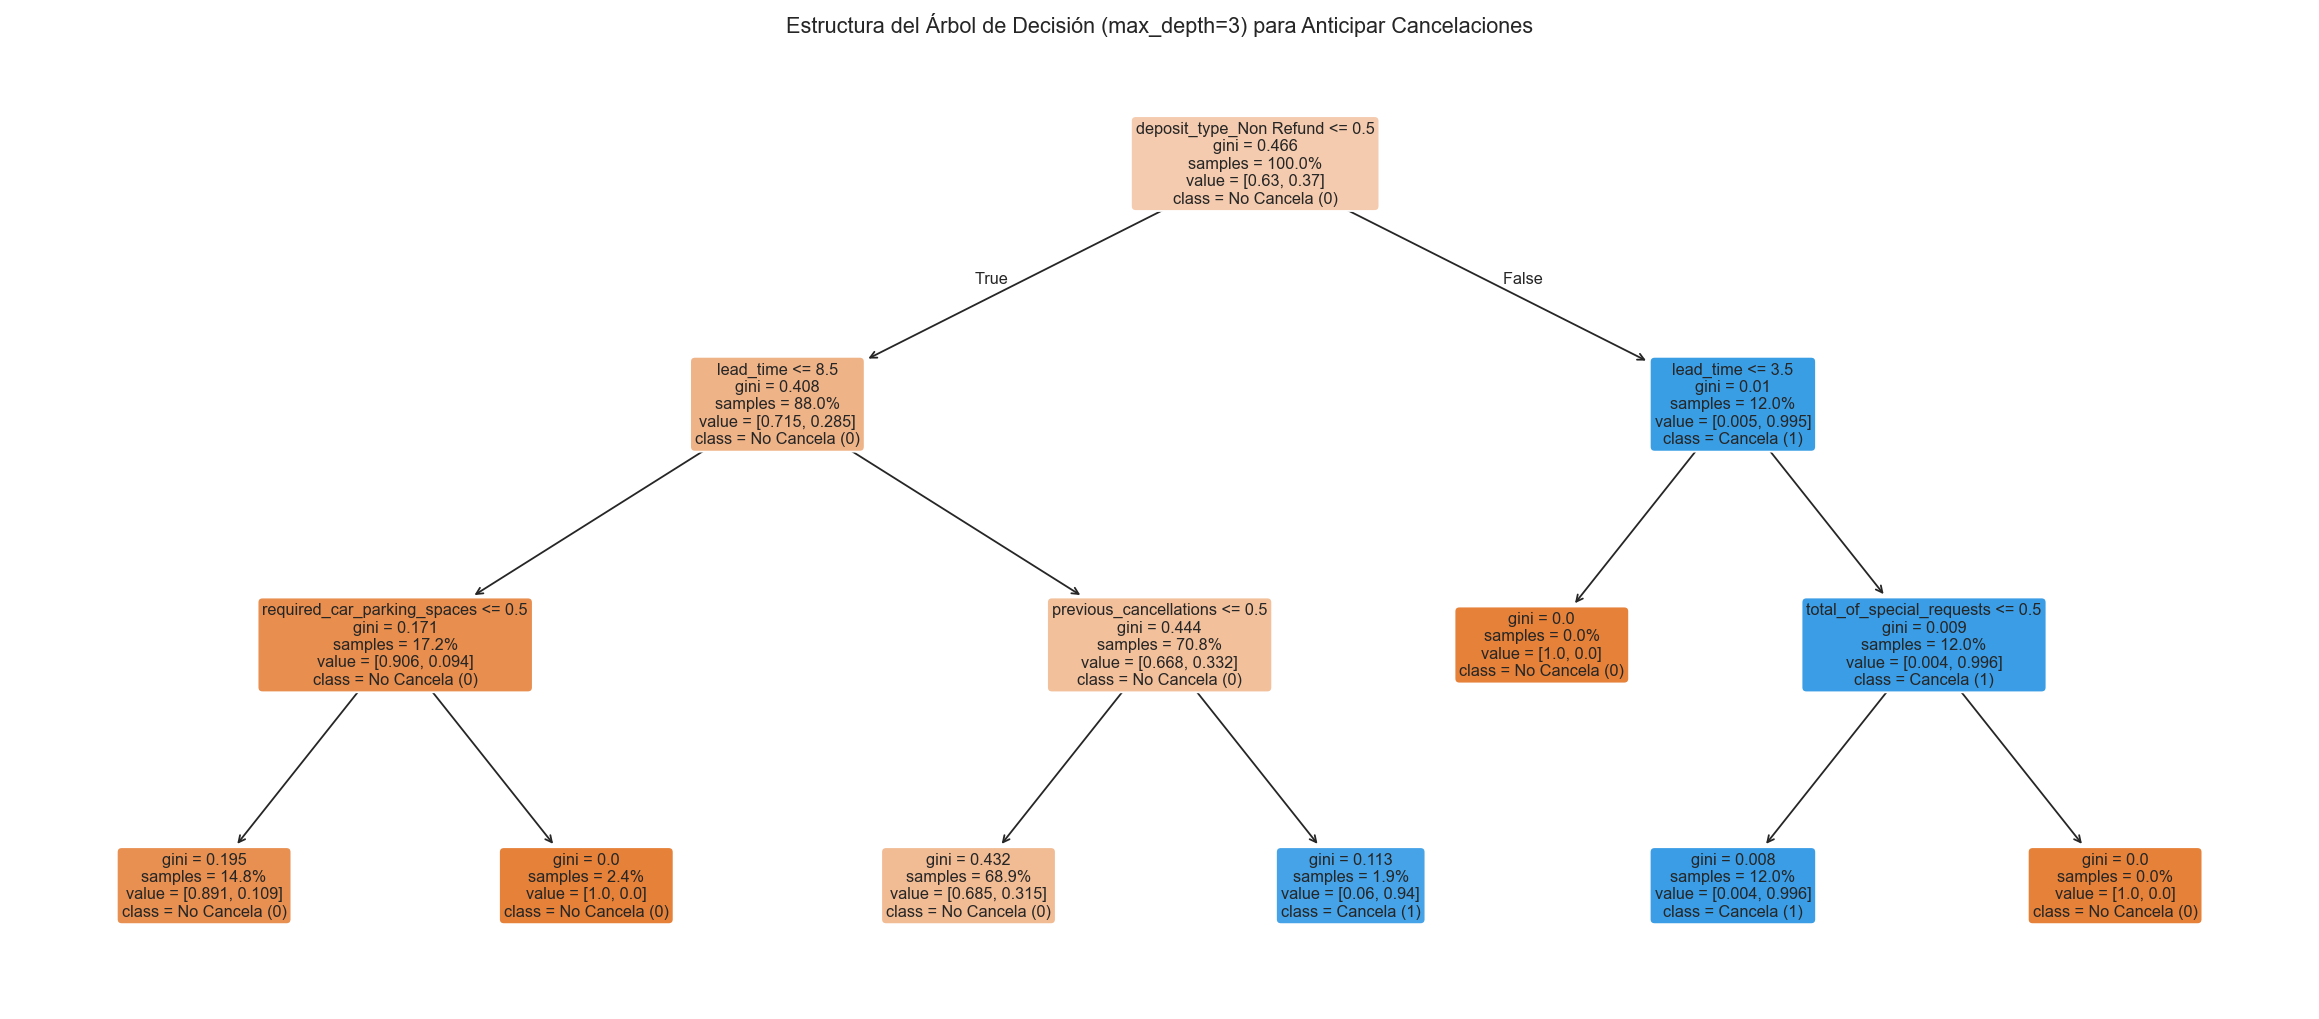

In [5]:
# Visualización gráfica de las reglas del Árbol de Decisión entrenado
plt.figure(figsize=(18, 8))
plot_tree(
    modelo,
    feature_names=X_train.columns,
    class_names=["No Cancela (0)", "Cancela (1)"],
    filled=True,
    rounded=True,
    fontsize=9,
    proportion=True
)
plt.title("Estructura del Árbol de Decisión (max_depth=3) para Anticipar Cancelaciones")
plt.tight_layout()
plt.show()

## 5. Inspección e Interpretación de Predicciones, Probabilidades y Decisiones

Siguiendo las actividades de la Unidad N° 5, registramos las predicciones del conjunto de prueba en **DuckDB** para analizar mediante **SQL** tanto las primeras observaciones como los casos de probabilidad alta, baja e incierta (cercana a `0.50`).

In [6]:
# Registro de los resultados de prueba en DuckDB para análisis con SQL
resultados_test = X_test[["lead_time", "previous_cancellations", "total_of_special_requests", "adr"]].copy()
resultados_test["resultado_real"] = y_test.to_numpy()
resultados_test["prediccion"] = y_pred
resultados_test["probabilidad_cancelacion"] = probabilidad_cancelacion.round(3)
resultados_test["distancia_a_0_5"] = (resultados_test["probabilidad_cancelacion"] - 0.5).abs().round(3)

con.register("predicciones_test", resultados_test.reset_index(drop=True))

# Consulta SQL: Muestra de predicciones con lectura inicial de riesgo
con.sql("""
SELECT
    lead_time,
    previous_cancellations,
    total_of_special_requests,
    adr,
    resultado_real,
    prediccion,
    probabilidad_cancelacion,
    CASE
        WHEN probabilidad_cancelacion < 0.30 THEN 'Probabilidad baja (< 0.30)'
        WHEN probabilidad_cancelacion > 0.70 THEN 'Probabilidad alta (> 0.70)'
        ELSE 'Caso intermedio / incierto (0.30 a 0.70)'
    END AS lectura_inicial
FROM predicciones_test
LIMIT 12
""").df()

,lead_time,previous_cancellations,total_of_special_requests,adr,resultado_real,prediccion,probabilidad_cancelacion,lectura_inicial
0,166,0,0,110.00,1,1,0.996,Probabilidad alta (> 0.70)
1,20,0,0,116.00,0,0,0.315,Caso intermedio / incierto (0.30 a 0.70)
2,56,0,3,222.00,0,0,0.315,Caso intermedio / incierto (0.30 a 0.70)
3,78,0,1,326.33,0,0,0.315,Caso intermedio / incierto (0.30 a 0.70)
4,99,0,0,108.00,1,0,0.315,Caso intermedio / incierto (0.30 a 0.70)
5,189,0,1,158.00,0,0,0.315,Caso intermedio / incierto (0.30 a 0.70)
6,199,0,1,123.00,0,0,0.315,Caso intermedio / incierto (0.30 a 0.70)
7,277,0,2,96.30,0,0,0.315,Caso intermedio / incierto (0.30 a 0.70)
8,14,0,0,178.80,1,0,0.315,Caso intermedio / incierto (0.30 a 0.70)
9,273,0,2,108.95,1,0,0.315,Caso intermedio / incierto (0.30 a 0.70)


## 6. Interpretación Crítica del Primer Modelo (Cierre de la Entrega 5)

1. **Diferencia entre categoría predicha (`prediccion`) y probabilidad estimada (`probabilidad_cancelacion`):**
   * La categoría predicha reduce la salida del modelo a una etiqueta binaria rígida (`0` o `1`, usando por defecto el umbral de `0.50`), mientras que la **probabilidad estimada** informa el grado de inclinación del nodo hoja del árbol (por ejemplo, una probabilidad de `0.996` en reservas con depósito `Non Refund` o con historial de cancelaciones previas frente a una probabilidad intermedia de `0.369` en reservas generales con más de 8 días de anticipación).
2. **Importancia de actuar con cautela en casos intermedios y límites del modelo:**
   * En las hojas donde la probabilidad se ubica alrededor de `0.369` (36,9% de riesgo de cancelación), clasificar todas esas reservas simplemente como `0 (No Cancela)` oculta que más de un tercio de ellas sí terminará cancelándose.
   * Una predicción **no es una verdad absoluta ni una relación causal**: antes de aplicar una acción comercial (como exigir prepago, enviar un recordatorio o sobrevender habitaciones) es indispensable evaluar formalmente la matriz de confusión y los costos de los errores de clasificación, tarea que desarrollamos en profundidad en la **Entrega 6**.

In [7]:
con.close()
print("🔒 Conexión cerrada correctamente.")

🔒 Conexión cerrada correctamente.
